# From a GEO series to an annotation

This notebook starts from the GEO page for [GSE266598](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE266598), a mouse calvarial bone-defect experiment (C57BL/6). The series has two 10x samples: a TrkA agonist (GA) and a vehicle control.

`geo_info` reads the series record and prints each sample. `read_geo` downloads the samples named in the next cell. `prepare` clusters the counts. `run` collects the marker score, the name model, and the ML model, and writes a title. Open the notebook from the repository root so `data/gguf1106` is the weights folder from the load-model tutorial.


In [1]:
%matplotlib inline
import os
from pathlib import Path

os.environ.setdefault(
    "LLAMA_SERVER",
    "/tmp/llama-b12180/llama-b12180/llama-server",
)
import scanpy as sc
import annotuneagent as ata

sc.settings.verbosity = 1
sc.set_figure_params(dpi=100, frameon=False)


## Read the series record

`geo_info` accepts the accession or the GEO URL. It downloads the series record only. The count matrices stay on the server. The printed lines are the sample titles, GSM accessions, and characteristics used in the next cell.


In [2]:
info = ata.geo_info(
    "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE266598"
)
print(info)


GSE266598  Boosting Sensory Nerve-to-Bone Interactions Enhances Hedgehog Mediated Calvarial Bone Repair
Mus musculus
Any person that has broken a bone can attest to the existence of sensory innervation of the skeleton. Beyond afferent functions, sensory neurons have been implicated in the orchestration of bone repair via the release of neuroregulatory signals. Yet, these neurosecretory effects have principally been deciphered through loss-of-function studies. Indeed, the potential therapeutic benefit of boosting nerve-to-bone interactions remains cursorily studied. Here, using a mouse calvarial bone defect model, pharmacologic activation of TrkA with a small molecule partial agonist induced bone-associated nerve ingrowth and significantly improved calvarial bone healing. Single-cell RNA sequencing analysis of cells from the defect site revealed shifts in cluster proportions, with enrichment of immune cell populations in TrkA agonist-treated mice. Within the skeletal cell lineage, TrkA 

## Download the samples

Both samples list a 10x mtx. The call uses the GSM accessions from the record above. `samples` can also be the GEO titles. Omit `samples` to download every sample in the series.

`groups` sets `obs["group"]`. The text is stored as written. `obs["sample"]` stays the GEO title. The treatment sentence from the record is kept in `obs["treatment"]`. Each compressed matrix is about 110–125 MB. A file already in `~/.cache/annotuneagent/geo` is not downloaded again.


In [3]:
adata = ata.read_geo(
    info,
    samples=["GSM8252262", "GSM8252263"],
    groups="GSM8252262: GA  GSM8252263: vehicle",
)
print(adata)
print(adata.obs.groupby(["sample", "group"], observed=True).size())


Cranial bone with a defect at the center, GA: (9322, 32285)  GSM8252262  group GA


Cranial bone with a defect at the center, Control: (8718, 32285)  GSM8252263  group vehicle


AnnData object with n_obs × n_vars = 18040 × 32285
    obs: 'geo_accession', 'tissue', 'cell_line', 'cell_type', 'strain', 'treatment', 'sample', 'group'
    var: 'gene_ids', 'feature_types'
    uns: 'geo'
sample                                             group  
Cranial bone with a defect at the center, GA       GA         9322
Cranial bone with a defect at the center, Control  vehicle    8718
dtype: int64


## Prepare

`adata.X` holds raw counts. `batch_key="sample"` fits QC and Scrublet inside each GEO sample, and names the two batches for Harmony. Harmony changes the neighbor graph used for Leiden and UMAP. Marker scores still read the log1p matrix. `doublet_chip="10k"` sets Scrublet's expected multiplet rate at 0.8% per 1,000 cells left after QC. `resolution=None` uses 0.4. `denoise=False` leaves AmbiDose ambient subtraction off. That step needs each sample's unfiltered droplet matrix, passed as `raw`. This series only deposits the sample count matrices.


prepare  drop genes with no counts ...


prepare  drop genes with no counts  0.5s  5160 genes


prepare  QC ...


prepare  QC  1.4s  1375 cells removed, 16665 remain, per sample


prepare  doublets ...


prepare  doublets  115.0s  423 removed in 2 samples


... (43 outputs left out)

prepare  UMAP ...


prepare  UMAP  9.1s


prepare  done  137.0s  16242 cells, 21 clusters


  batch correction harmony

Cells
  input            18,040
  AmbiDose         off
  QC               -1,375 -> 16,665
Cranial bone with a defect at the center, Control: 8,718 cells, 1,131 removed
  total counts: 125 to 1,905,265, 0 removed (0 below, 0 above)
  genes per cell: 243 to 56,419, 296 removed (296 below, 0 above)
  percent counts in top 20 genes: -7.4 to 46.5, 935 removed (0 below, 935 above)
  mitochondrial percent: 10.7 and 8, 507 removed
Cranial bone with a defect at the center, GA: 9,322 cells, 244 removed
  total counts: 320 to 370,213, 0 removed (0 below, 0 above)
  genes per cell: 212 to 27,485, 144 removed (144 below, 0 above)
  percent counts in top 20 genes: -33.8 to 87, 131 removed (0 below, 131 above)
  mitochondrial percent: 21.6 and 8, 154 removed
  Scrublet         -423 -> 16,242
    Cranial bone with a defect at the center, Control: 7,587 cells, 223 removed, threshold 0.1183, expected 6.1%
    Cranial bone with a defect at the center, GA: 9,078 cells, 200 rem

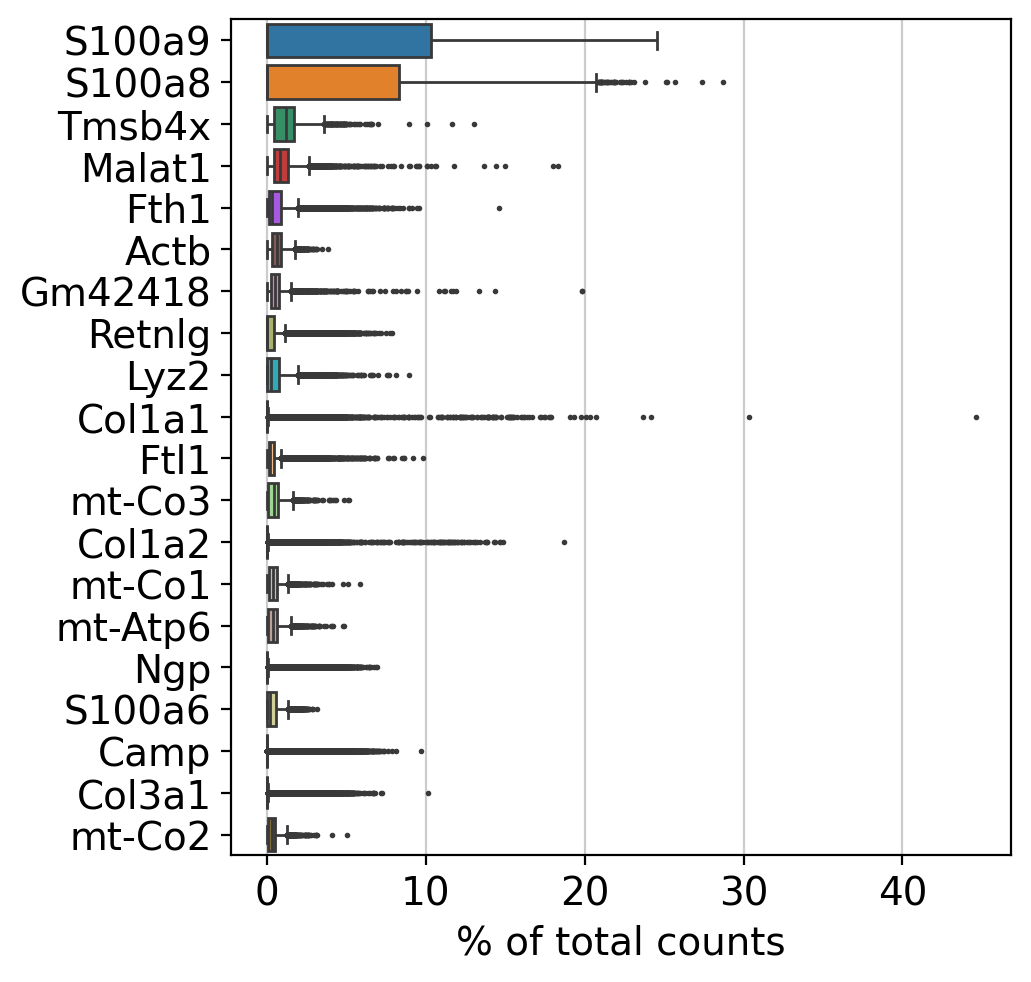

/home/lieber/AnnoTuneAgent/src/annotuneagent/prepare.py:390: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


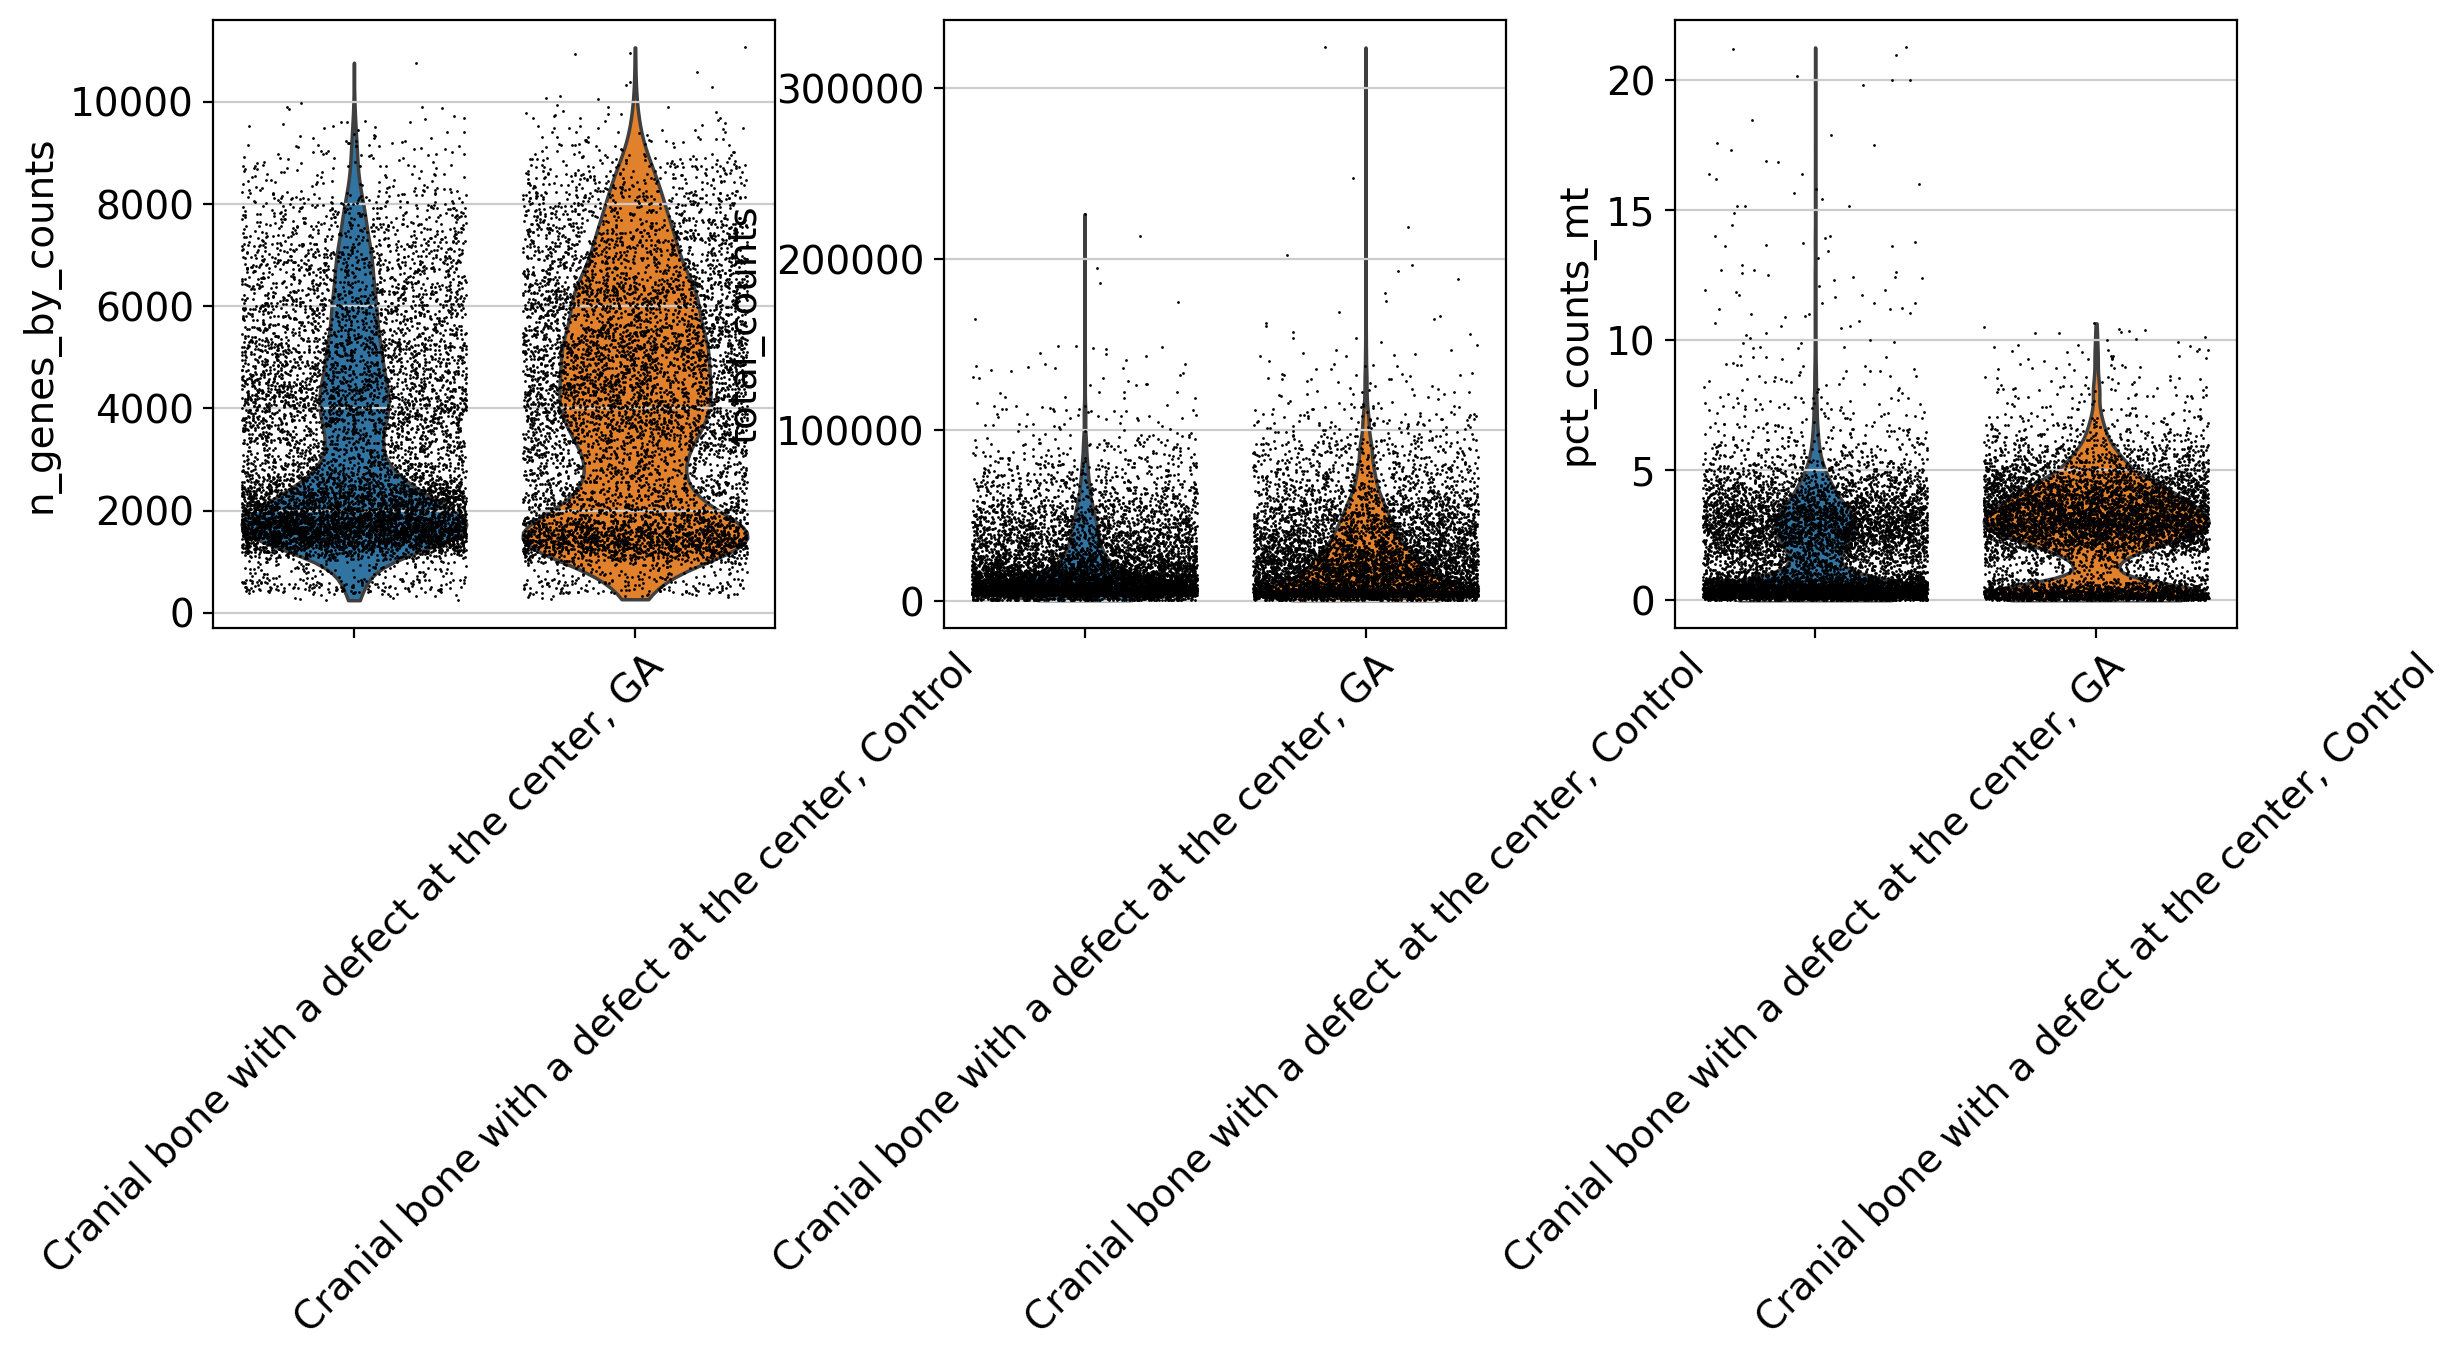

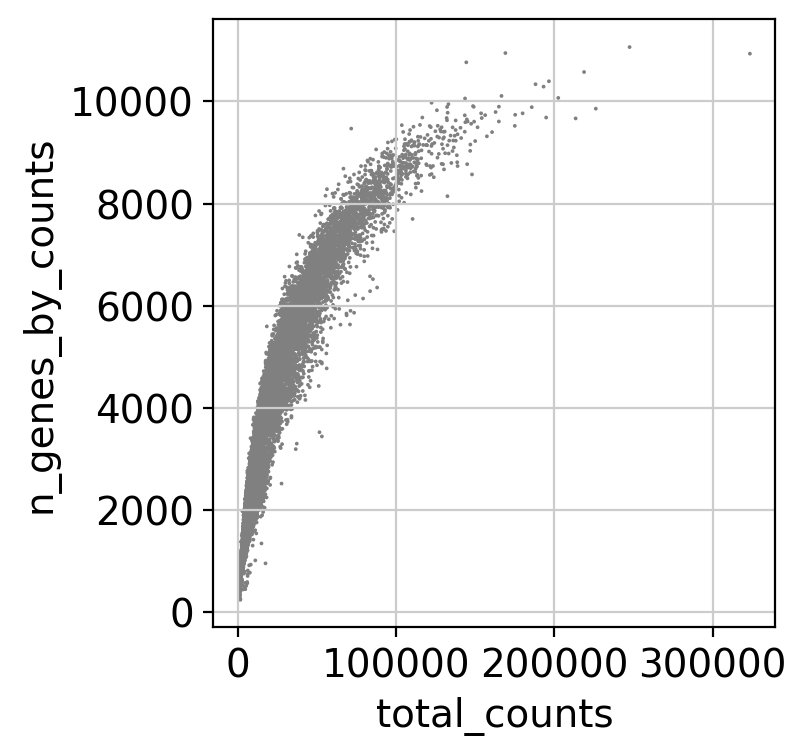

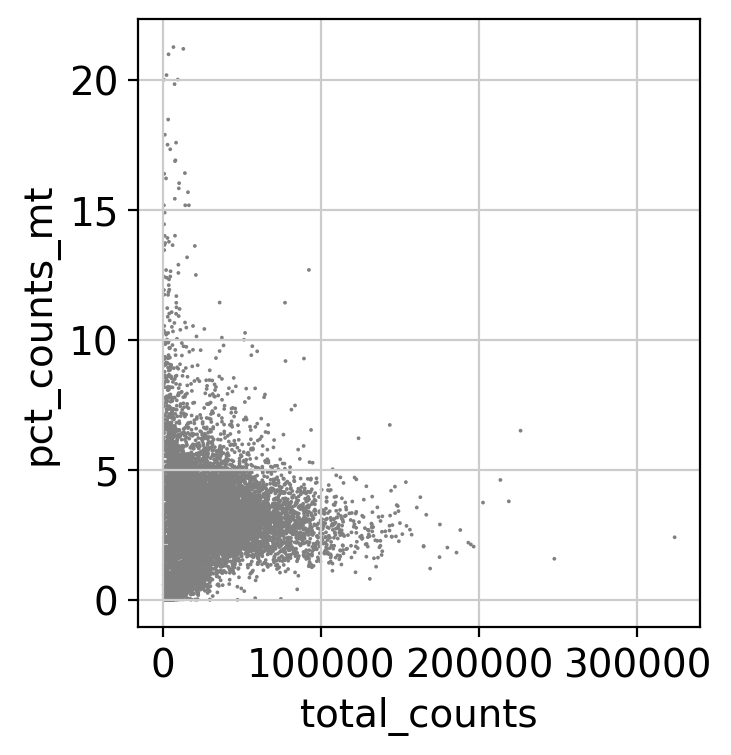

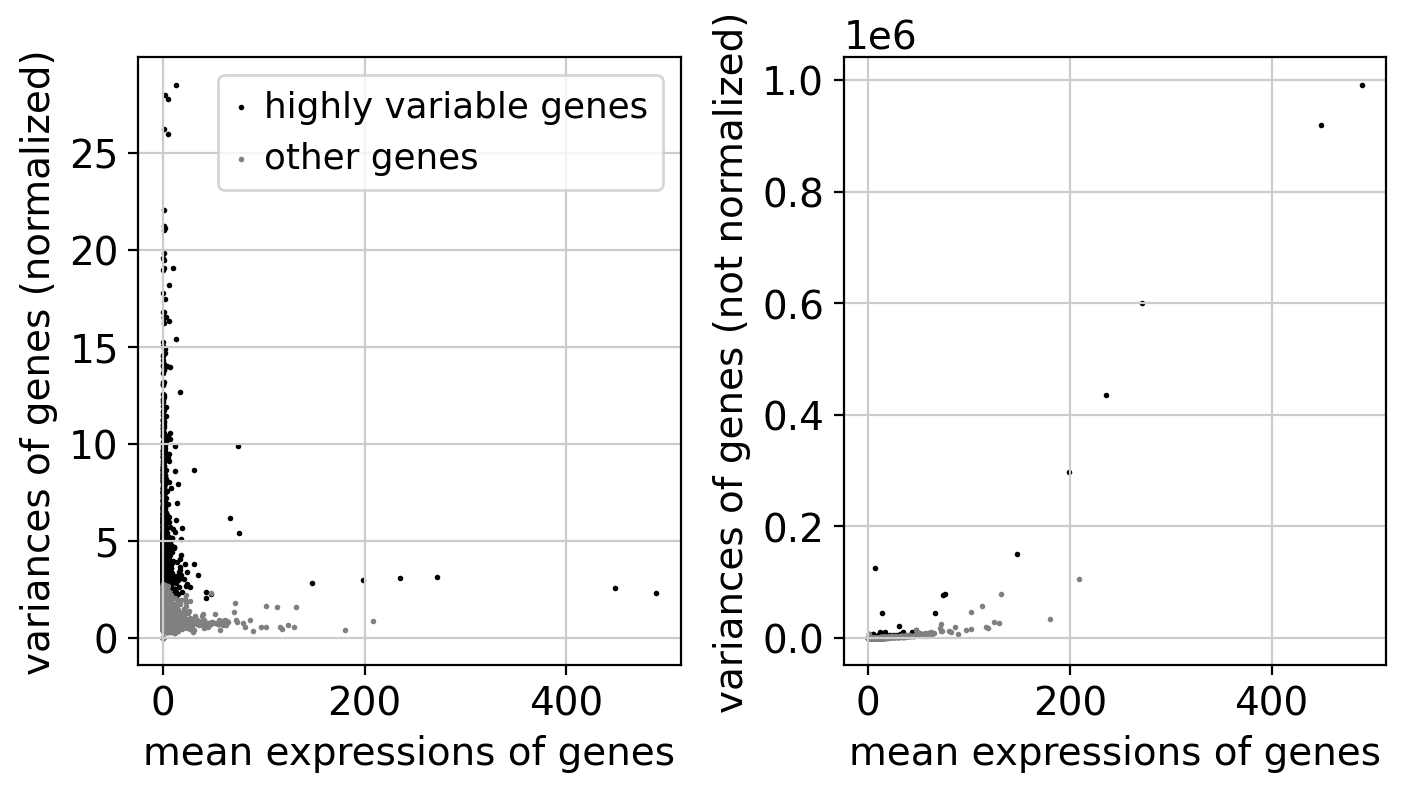

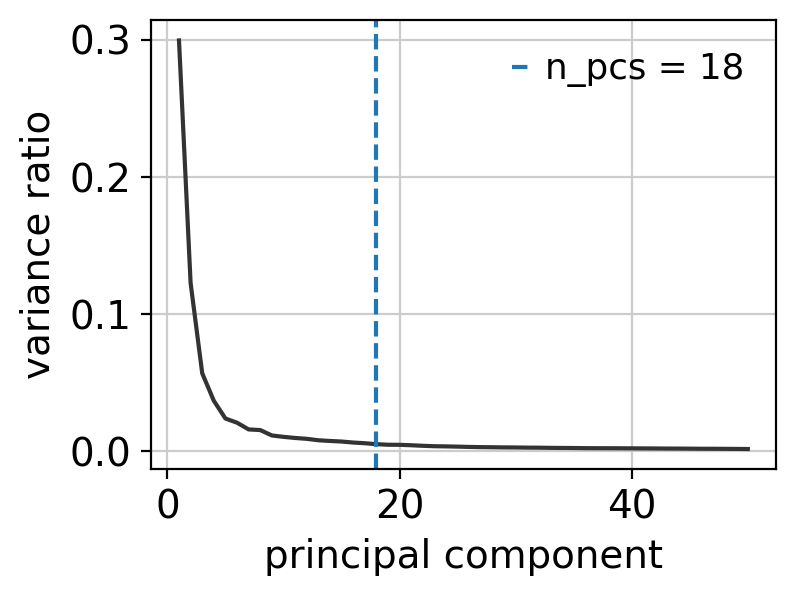

leiden
0     1176
1      660
2     1657
3      848
4     2123
5       83
6      552
7     2300
8      424
9     1569
10     418
11     868
12     542
13     518
14     282
15     709
16     656
17     124
18     132
19     451
20     150
Name: count, dtype: int64


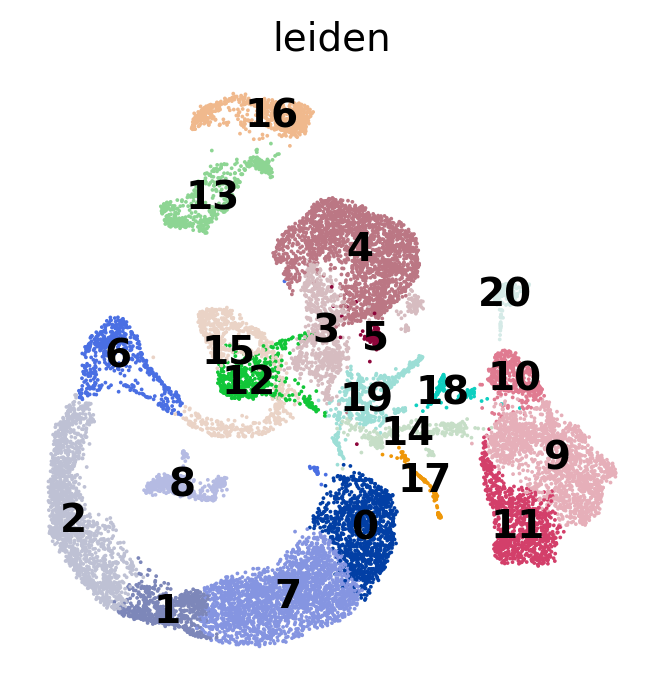

In [4]:
adata = ata.prepare(
    adata,
    species="mouse",
    batch_key="sample",
    batch_correction="harmony",  # none, harmony, combat, scanorama, scvi, scvi+harmony
    doublet_method="scrublet",  # none, scrublet, solo
    doublet_chip="10k",  # 10k is 0.8% per 1,000 cells; 20k is 0.4% per 1,000
    denoise=False,
    raw=None,
    resolution=None,  # None keeps 0.4; a number is used as given
    n_pcs=None,  # None uses the variance elbow; scvi modes use 30
    n_top_genes=None,  # None keeps 2000 seurat_v3 genes
    norm="log1p",
    scfair=False,
    max_pct_mt=None,
    cluster_key="leiden",
    n_neighbors=15,
    nmads=5,
    show=True,
)


## Annotation

The series tissue is calvaria. `tissue="bone"` adds the bone page (osteoblast, osteoclast, osteocyte) to the core dictionary. Immune cells and fibroblasts stay on the core page. `subcluster=True` splits an unresolved cluster once.

This call collects the marker score, the name result, and the ML result. A judgment writes the title. The name model copies a cell-type name from the marker dictionary. The ML model reads the measured candidates and copies a name from that list. A cluster can stay unnamed.


run  score markers ...


run  score markers  0.9s  19 of 21 clusters labeled


run  subcluster ...


/home/lieber/AnnoTuneAgent/src/annotuneagent/workflow.py:696: UserWarning: Ignoring svd_solver='full' and using arpack, sklearn.decomposition._pca.PCA (with sparse input) only supports dict_keys(['arpack', 'covariance_eigh']).
  sc.pp.pca(part, n_comps=n_comps, svd_solver="full")


run  subcluster  0.6s  2 clusters


run  Wilcoxon ...


... (71 outputs left out)

mouse, bone, 282 cells. What cell type is this cluster?
Enriched versus other cells: Gm42418 (in 1.00, out 1.00, logfc 1.54); Rpl41 (in 0.96, out 0.97, logfc 1.78); Rplp1 (in 0.96, out 0.90, logfc 2.04); Rpl37a (in 0.94, out 0.96, logfc 1.38); Rps24 (in 0.95, out 0.90, logfc 1.68); Eef1a1 (in 0.95, out 0.92, logfc 1.60); Rpl39 (in 0.92, out 0.88, logfc 1.72); Rpl6 (in 0.88, out 0.84, logfc 1.69); Rps3a1 (in 0.94, out 0.89, logfc 1.64); Rps2 (in 0.88, out 0.78, logfc 2.00).


run  done  102.7s  21 of 21 clusters named


,cluster,cells,marker,name,ml,label,hint,reason
0,0,1176,None,neutrophil,neutrophil,neutrophil,conflict: marker monocyte; close marker scores,evidence_conflict
1,1,660,neutrophil,neutrophil,neutrophil,neutrophil,None,evidence_agreement
2,2,1657,neutrophil,neutrophil,neutrophil,neutrophil,None,evidence_agreement
3,3,848,monocyte,monocyte,monocyte,monocyte,None,evidence_agreement
4,4,2123,monocyte,monocyte,monocyte,monocyte,None,evidence_agreement
5,5,83,osteoclast,osteoclast,osteoclast,osteoclast,None,evidence_agreement
6,6,552,granulocyte-monocyte progenitor,granulocyte-monocyte progenitor,neutrophil,granulocyte-monocyte progenitor,conflict: ML neutrophil,evidence_conflict
7,7,2300,neutrophil,neutrophil,neutrophil,neutrophil,None,evidence_agreement
8,8,424,T cell,T cell,NK cell,T cell,conflict: ML NK cell,evidence_conflict
9,9,1569,fibroblast,fibroblast,fibroblast,fibroblast,no marker passed,no_marker_passed


Doublets
  Scrublet removed 423
Cranial bone with a defect at the center, Control: 7,587 cells, 223 removed, threshold 0.1183, expected 6.1%
Cranial bone with a defect at the center, GA: 9,078 cells, 200 removed, threshold 0.2074, expected 7.3%
Dropped hypotheses
  gamma-delta T cell: missing positive markers: Trgc1, Trgc2, Trgc4
  megakaryocyte-erythroid progenitor: missing positive markers: Ca1
  erythroblast: missing positive markers: Ca2
  lymphatic endothelial cell: missing positive markers: Ccl21a
Review
  Order is for manual review. It is not an accuracy score.
  0  neutrophil [CL:0000775, pending]  conflict: marker monocyte; close marker scores
  6  granulocyte-monocyte progenitor [CL:0000557, pending]  conflict: ML neutrophil
  8  T cell [CL:0000084, pending]  conflict: ML NK cell
  14  megakaryocyte [CL:0000556, pending]  conflict: ML platelet; close marker scores
  18  endothelial cell [CL:0000115, pending]  conflict: ML pericyte
  19  plasmacytoid dendritic cell [CL:0000784

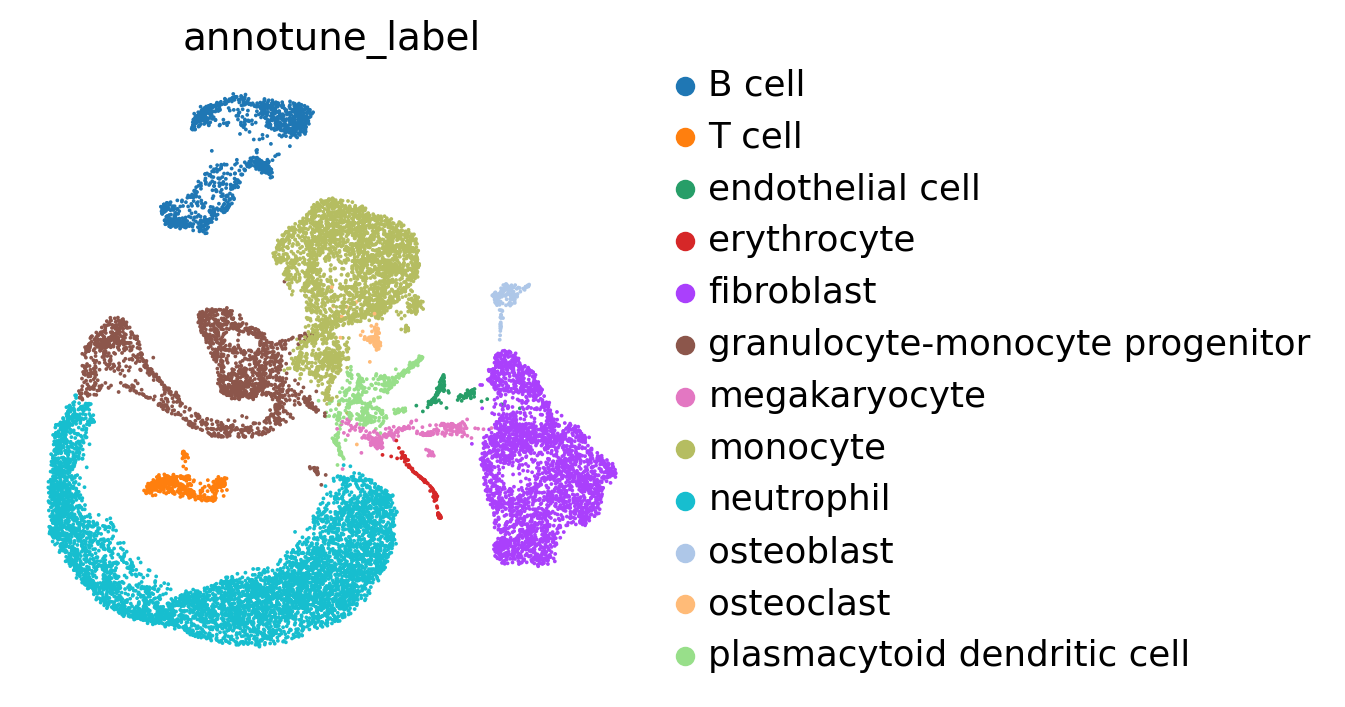

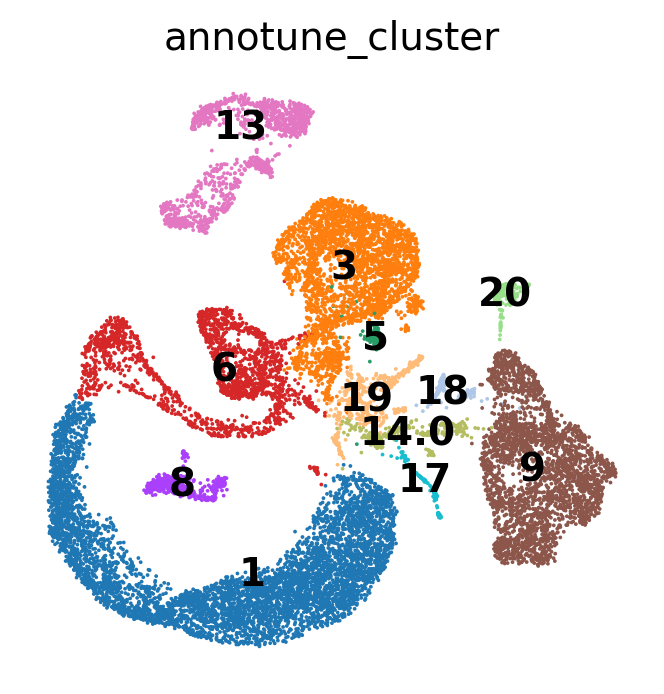

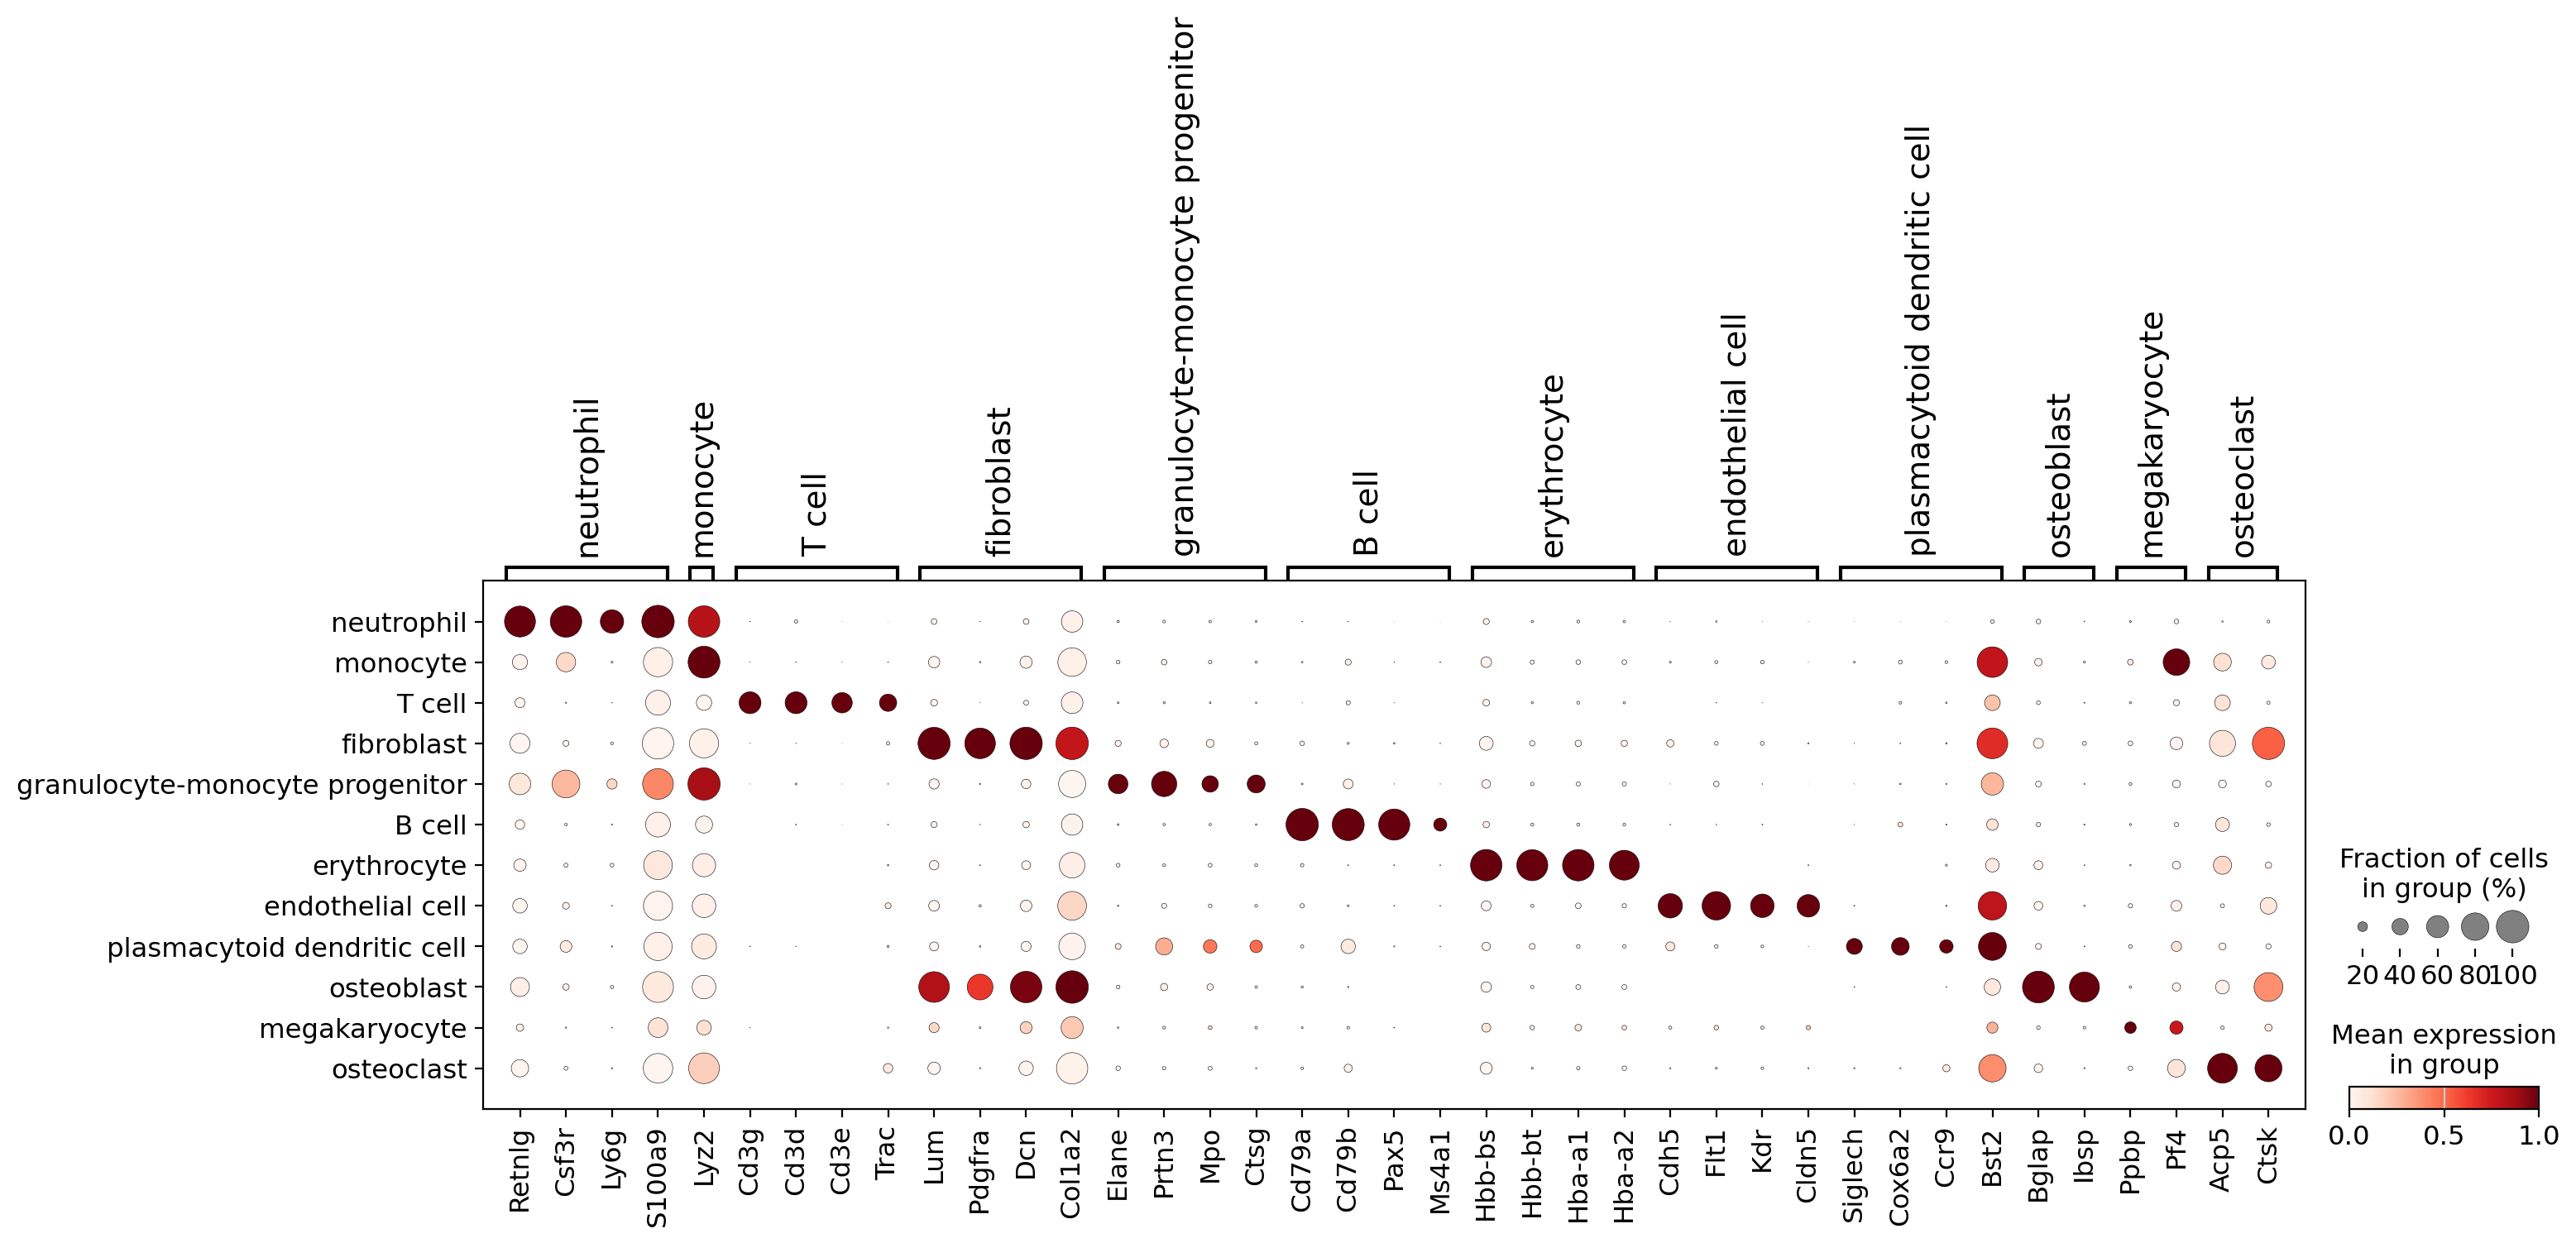

import pandas as pd
import scanpy as sc

# cluster2celltype maps each cluster id to its name.
# fine_order is the UMAP legend and the dotplot row order.
# marker_dict is the dotplot. Gene order inside a list is the column order.
cluster2celltype = {
    '1': 'neutrophil',
    '2': 'neutrophil',
    '3': 'monocyte',
    '4': 'monocyte',
    '5': 'osteoclast',
    '6': 'granulocyte-monocyte progenitor',
    '7': 'neutrophil',
    '8': 'T cell',
    '9': 'fibroblast',
    '10': 'fibroblast',
    '11': 'fibroblast',
    '12': 'granulocyte-monocyte progenitor',
    '13': 'B cell',
    '15': 'granulocyte-monocyte progenitor',
    '16': 'B cell',
    '17': 'erythrocyte',
    '18': 'endothelial cell',
    '19': 'plasmacytoid dendritic cell',
    '20': 'osteoblast',
    '0.0': 'neutrophil',
    '0.1': 'neutrophil',
    '0.2': 'neutrophil',
    '0.3': 'neutrophil',
    '0.4': 'neutrophil',
    '0.5': 'neutrophil',
    '14.0': 'megakaryocyte',
    '14.1': 'megakaryocyte',
    '14.2': 'megakaryocy

In [5]:
models = ata.local_models(Path("data/gguf1106"))
report = ata.run(
    adata,
    "leiden",
    species="mouse",
    tissue="bone",
    hypotheses=None,  # None uses the built-in dictionary
    user_hypotheses=None,
    min_margin=0.15,
    models=models,
    subcluster=True,
    min_subcluster_cells=40,
    label_key="annotune_label",
    dotplot_path=None,
    show=True,
)
print(adata.obs.groupby(["group", "annotune_label"], observed=True).size())
